In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import  missingno as msno

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [13]:
# Install dependencies as needed:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "Life Expectancy Data.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "kumarajarshi/life-expectancy-who",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:\n", df.head())

First 5 records:
        Country  Year      Status  Life expectancy   Adult Mortality  \
0  Afghanistan  2015  Developing              65.0            263.0   
1  Afghanistan  2014  Developing              59.9            271.0   
2  Afghanistan  2013  Developing              59.9            268.0   
3  Afghanistan  2012  Developing              59.5            272.0   
4  Afghanistan  2011  Developing              59.2            275.0   

   infant deaths  Alcohol  percentage expenditure  Hepatitis B  Measles   ...  \
0             62     0.01               71.279624         65.0      1154  ...   
1             64     0.01               73.523582         62.0       492  ...   
2             66     0.01               73.219243         64.0       430  ...   
3             69     0.01               78.184215         67.0      2787  ...   
4             71     0.01                7.097109         68.0      3013  ...   

   Polio  Total expenditure  Diphtheria    HIV/AIDS         GDP  Pop

In [14]:
df.shape

(2938, 22)

In [15]:
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [16]:
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling'],
      dtype='str')

In [17]:
df.info()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

<Axes: >

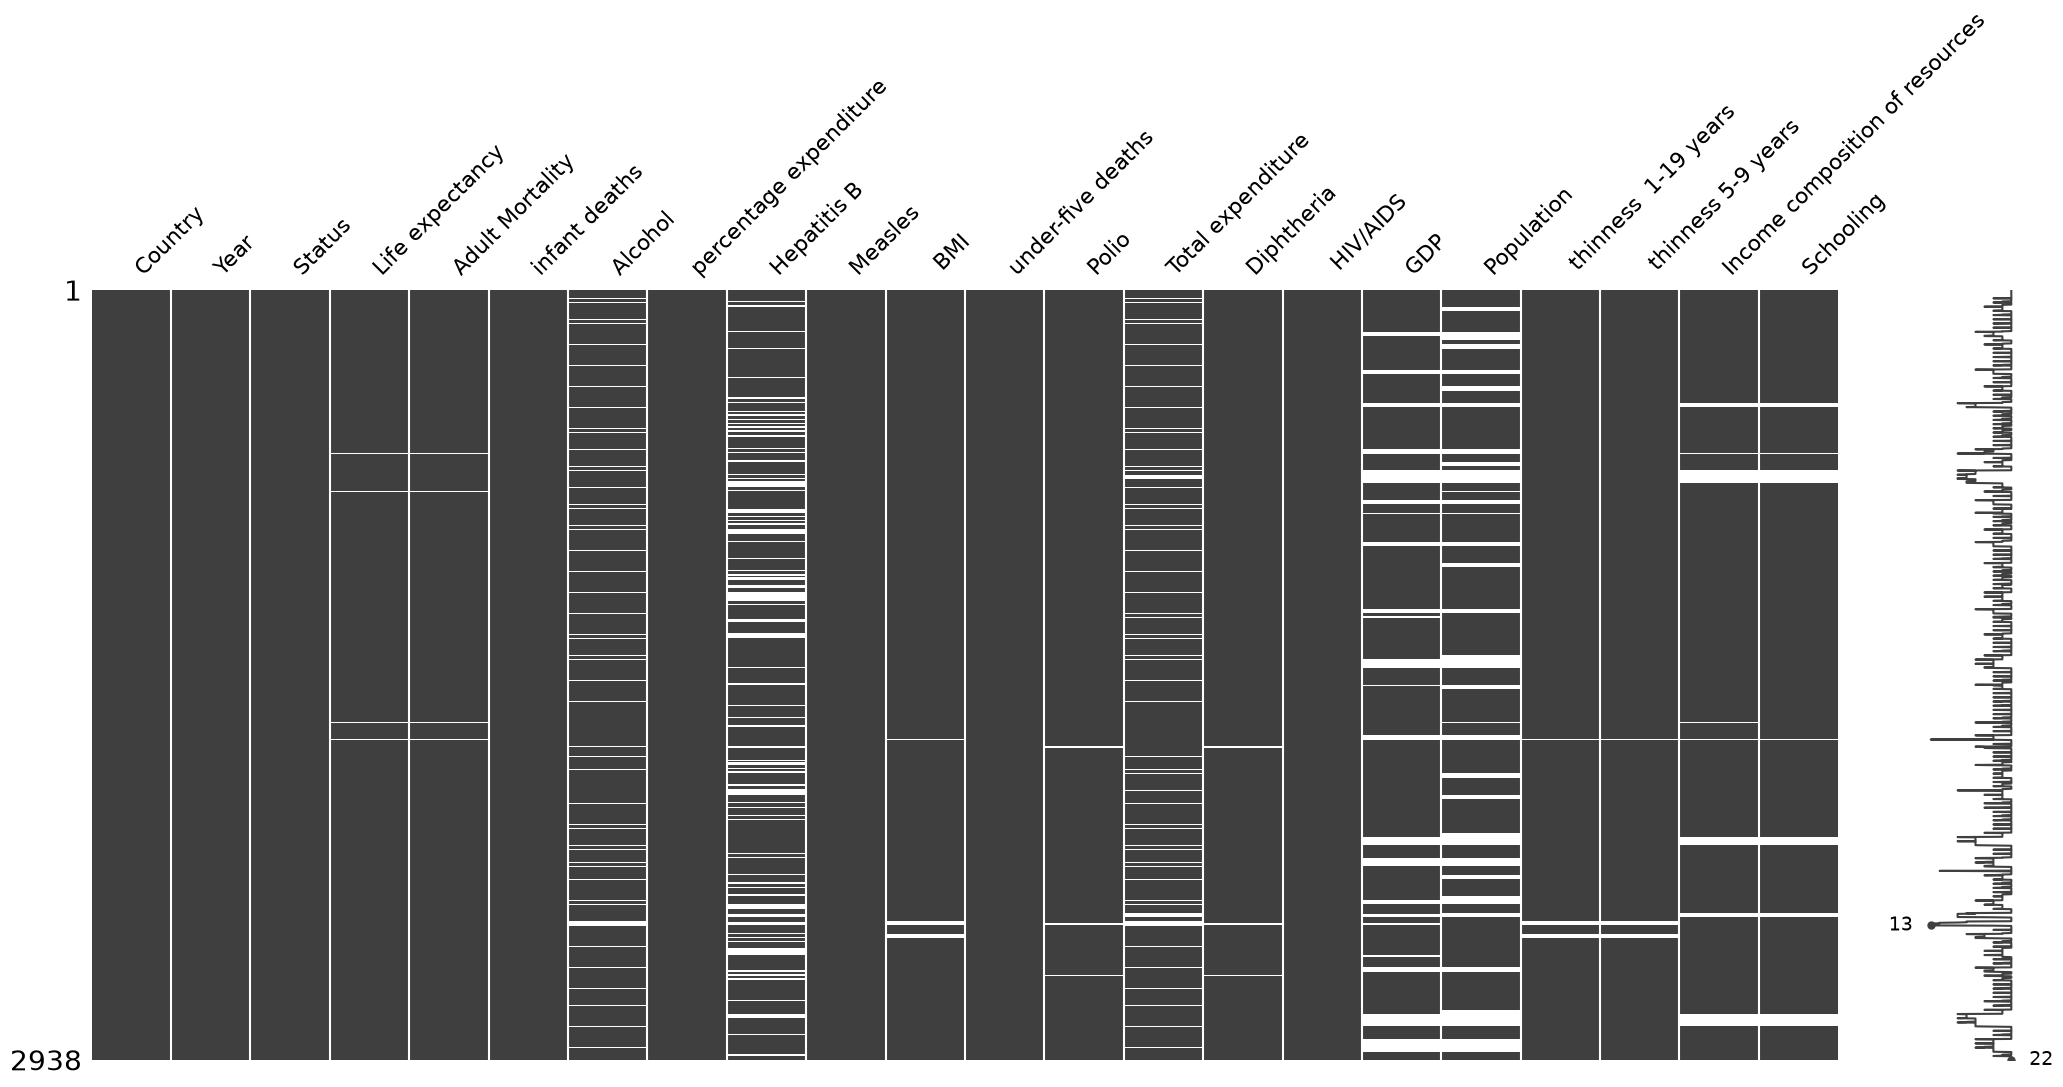

In [18]:
msno.matrix(df)

In [19]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
 thinness 5-9 years                 34
 thinness  1-19 years               34
 BMI                                34
Polio                               19
Diphtheria                          19
Life expectancy                     10
Adult Mortality                     10
dtype: int64

In [20]:
missing_percent = (df.isnull().mean() * 100)
missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

missing_percent

Population                         22.191967
Hepatitis B                        18.822328
GDP                                15.248468
Total expenditure                   7.692308
Alcohol                             6.603131
Income composition of resources     5.684139
Schooling                           5.547992
 thinness 5-9 years                 1.157250
 thinness  1-19 years               1.157250
 BMI                                1.157250
Polio                               0.646698
Diphtheria                          0.646698
Life expectancy                     0.340368
Adult Mortality                     0.340368
dtype: float64

In [21]:
bins = [0, 5, 20, 50, 100]

groups = pd.cut(
    missing_percent,
    bins=bins,
    labels=["<5%", "5–20%", "20–50%", ">50%"],
    include_lowest=True
)

print(groups.value_counts().sort_index())

<5%       7
5–20%     6
20–50%    1
>50%      0
Name: count, dtype: int64


In [22]:
def diagnose_mv(df, mv_column):# Inputs: a pandas DataFrame, the column that has missing values
    # for each feature (column in the dataset)
    # https://www.geeksforgeeks.org/python/loop-or-iterate-over-all-or-certain-columns-of-a-dataframe-in-python-pandas/
    for i in df:
        # https://www.geeksforgeeks.org/python/change-font-size-in-matplotlib/
        plt.rcParams.update({'font.size': 12})
        # https://www.geeksforgeeks.org/python/place-plots-side-by-side-in-matplotlib/
        # Plot a histogram of the feature using all rows (including rows where
        #mv_column is missing)
        # This is taken from earlier
    
        # Plot another histogram of the same feature but only using rows where
        # mv_column is not missing
        dfcnm = df.copy(deep=True)
        dfcnm.dropna(subset=mv_column)
    
        # Plot a bar chart showing the absolute difference between the two
        # histograms (bin by bin)
        dfcd=df.copy(deep=True)
        # https://www.geeksforgeeks.org/pandas/create-a-new-column-in-pandas-dataframe-based-on-the-existing-columns/
        dfcd["column_missing?"]=pd.isna(dfcd[mv_column])
        # https://seaborn.pydata.org/generated/seaborn.histplot.html
        sns.histplot(dfcd, x=i, hue="column_missing?")
        # Arrange plots left Histogram with all rows, middle rows with mv_column missing
        # right the bar chart showing the difference.
        plt.tight_layout()
        plt.show()
    return

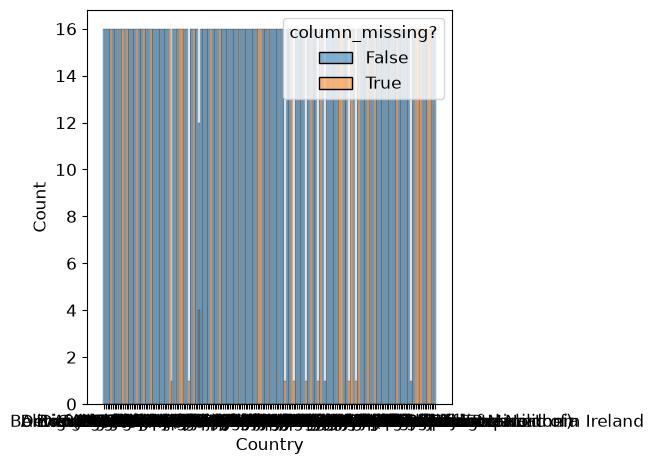

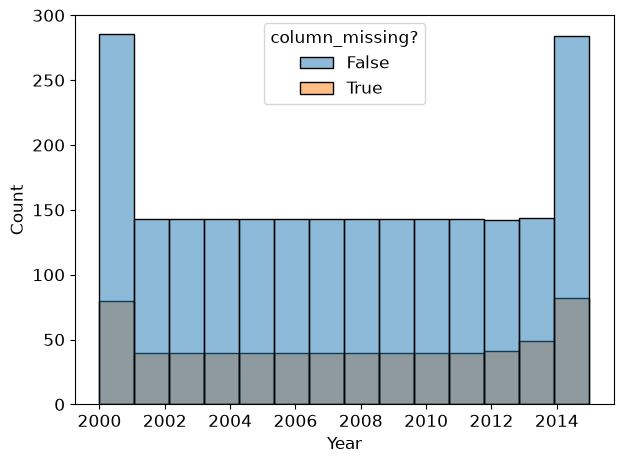

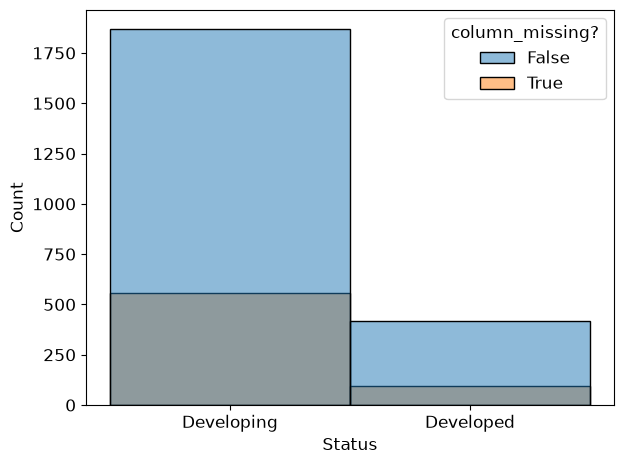

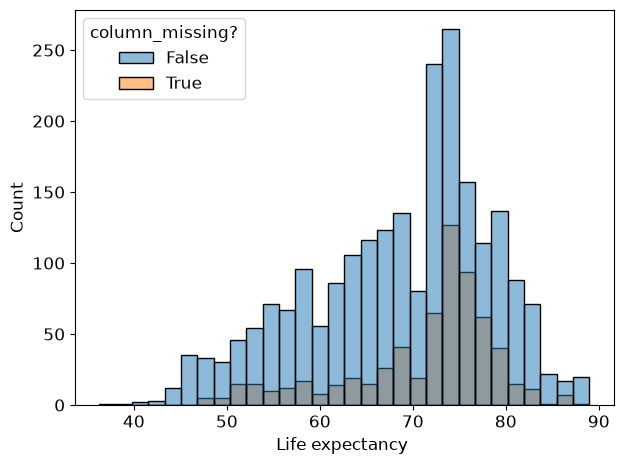

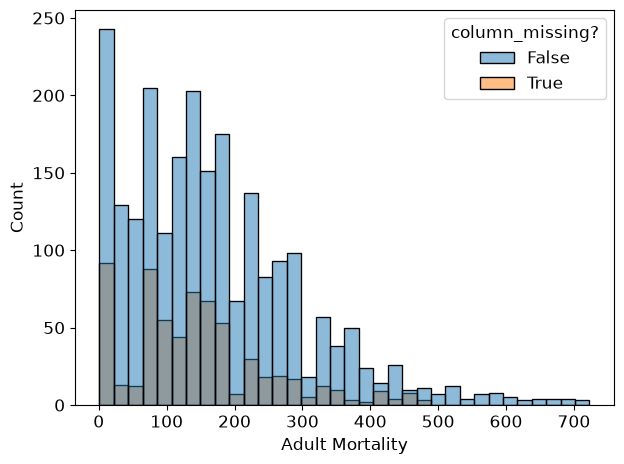

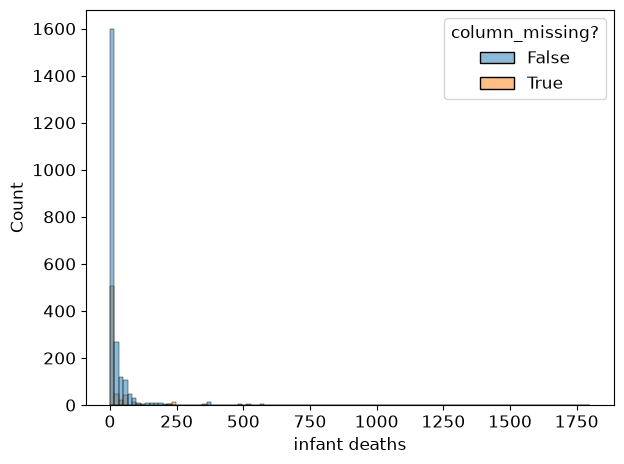

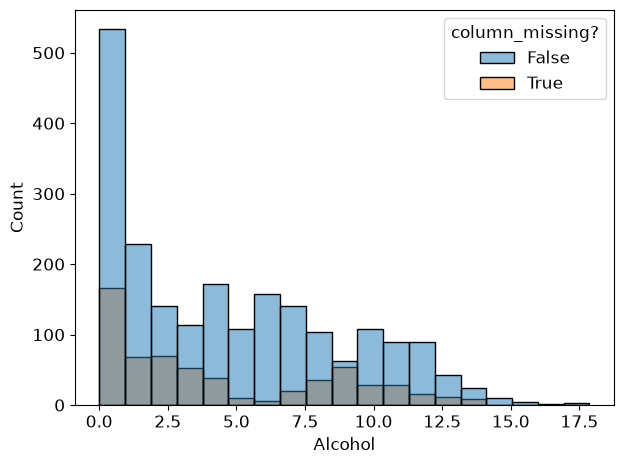

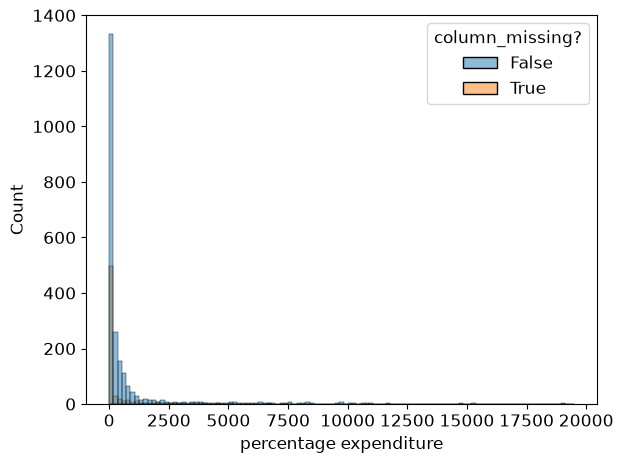

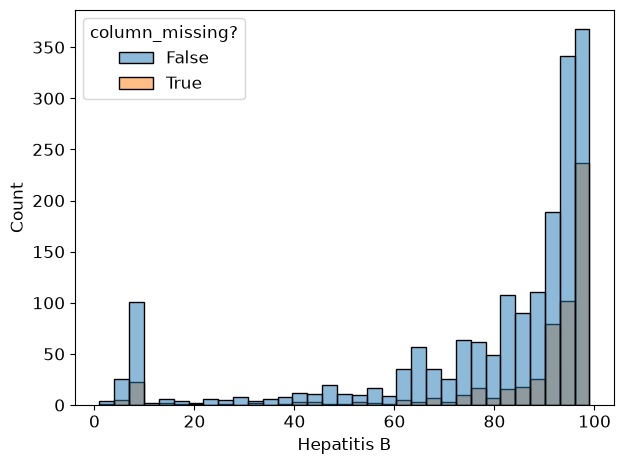

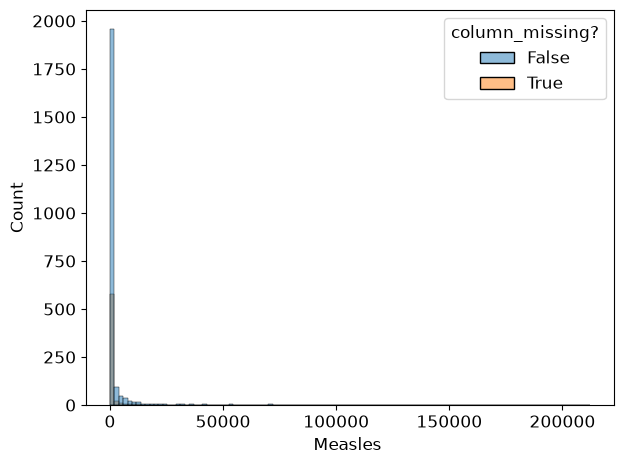

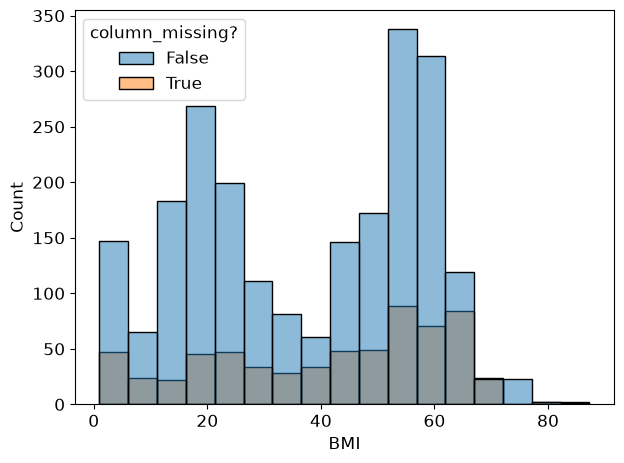

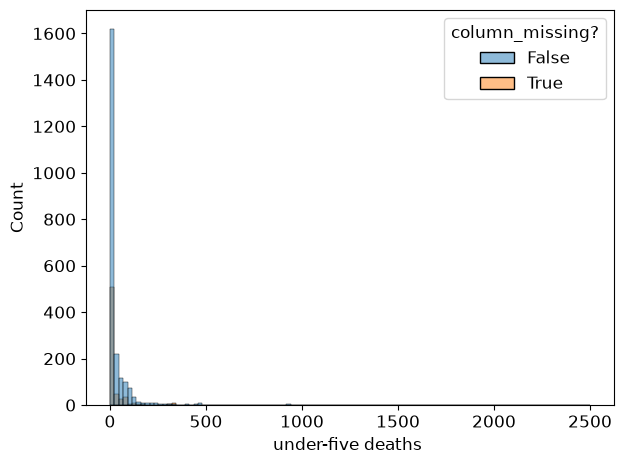

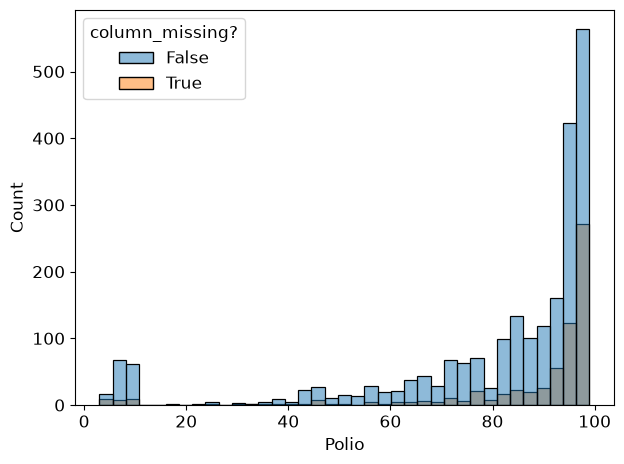

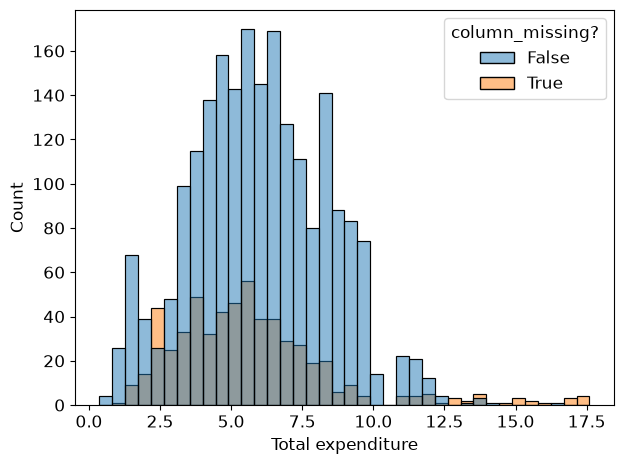

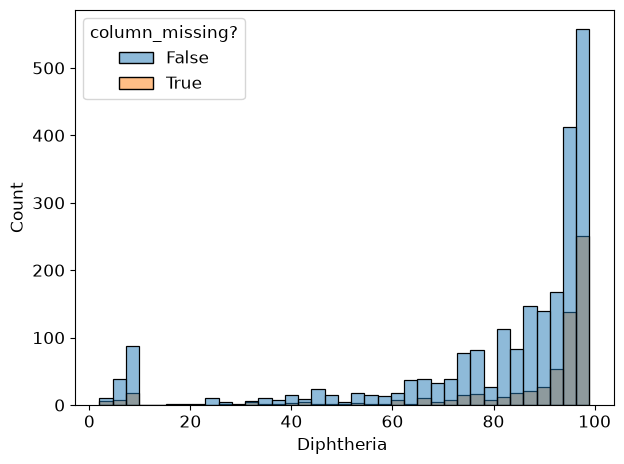

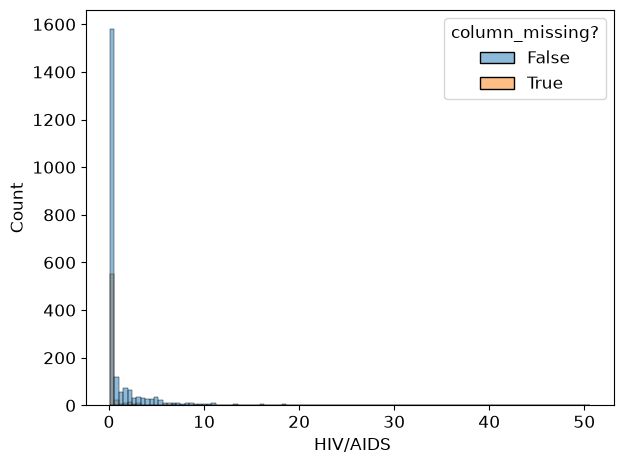

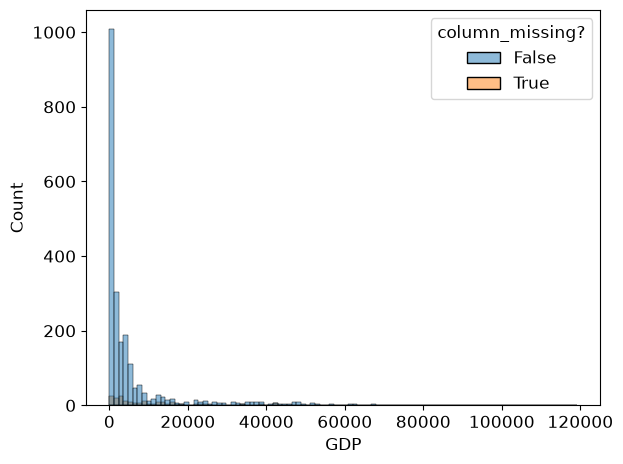

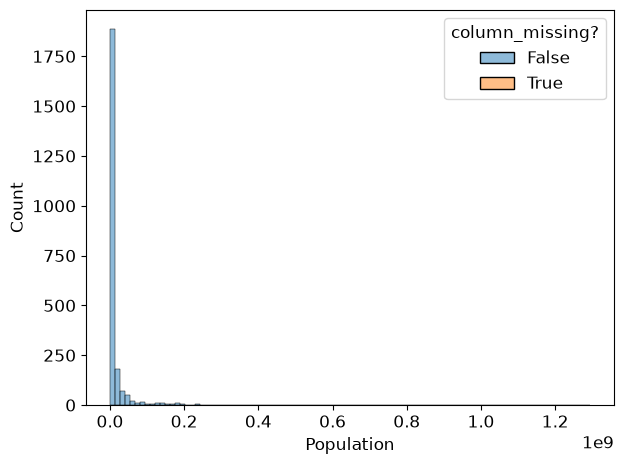

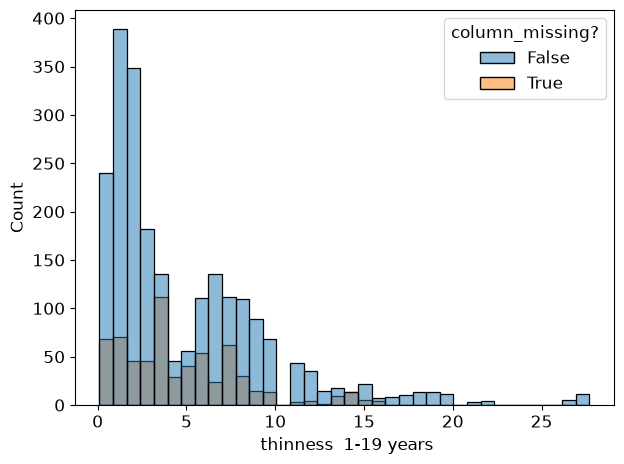

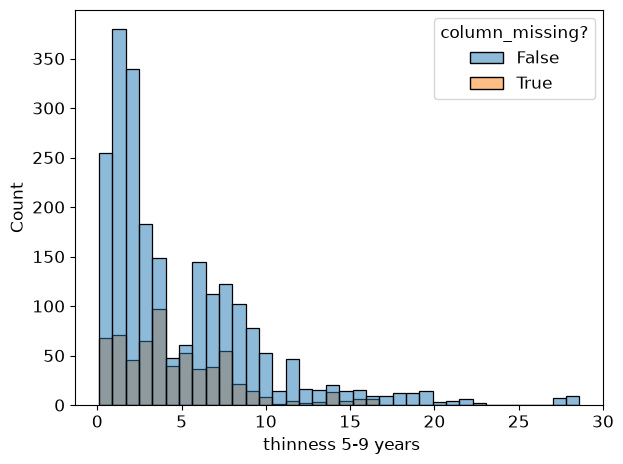

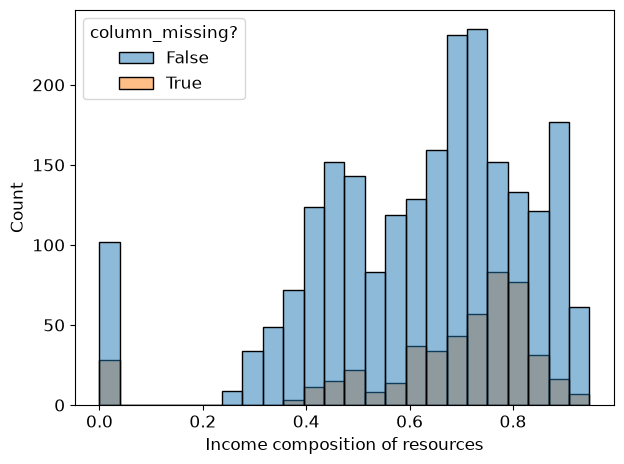

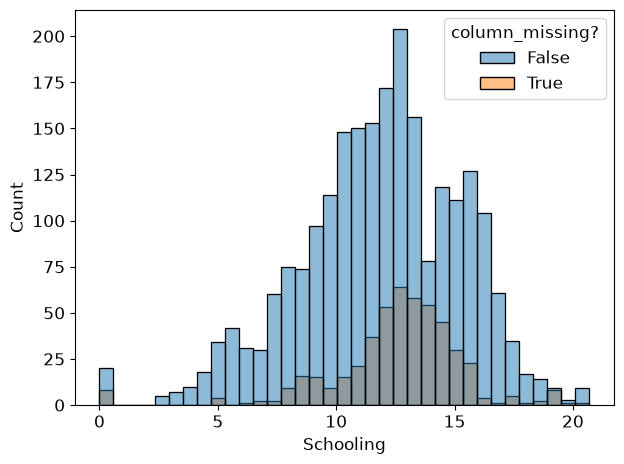

In [23]:
diagnose_mv(df, "Population")

Most of the shapes miss rather well, notable exceptions are BMI over 60 with 2 bins being almost full, Total Expenditure 2.5 having a larger amount of missing population rows than not, thinness 4-6 years having missing population value spikes.

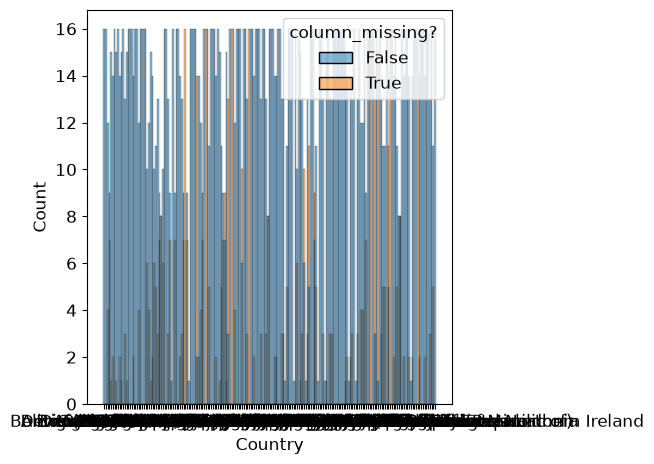

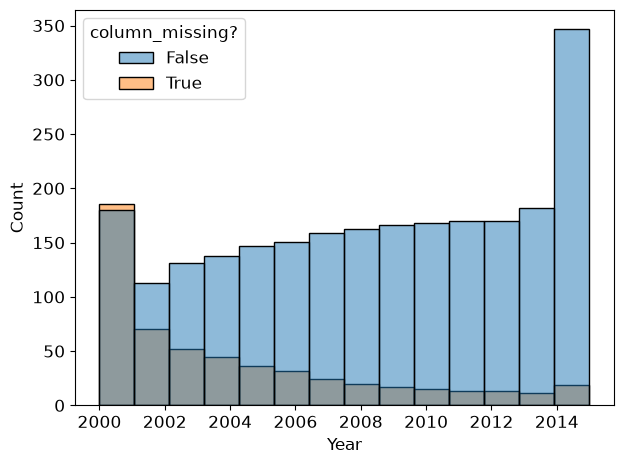

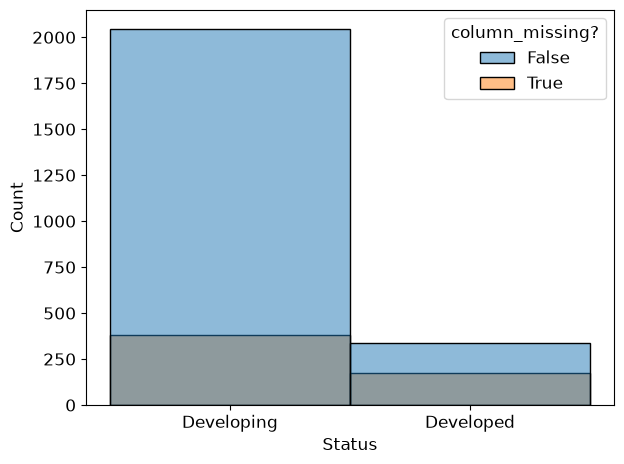

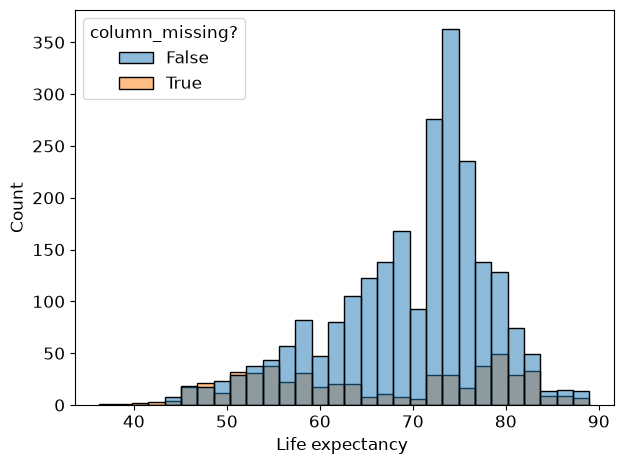

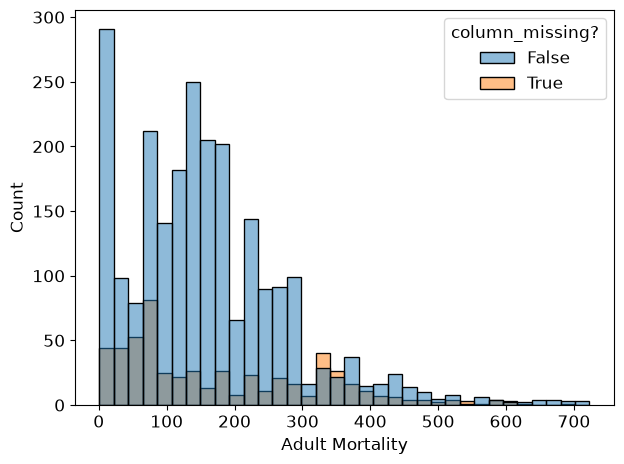

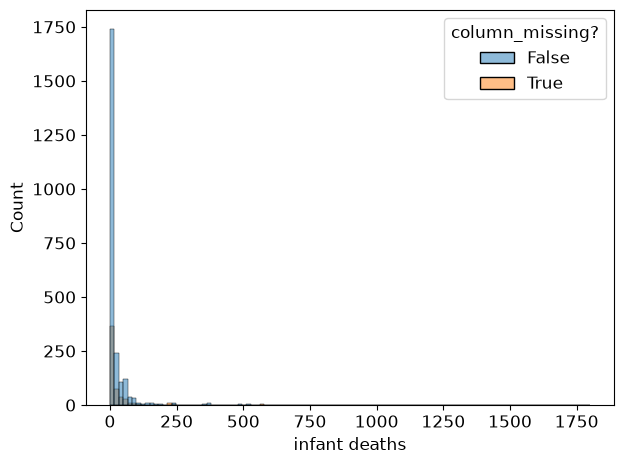

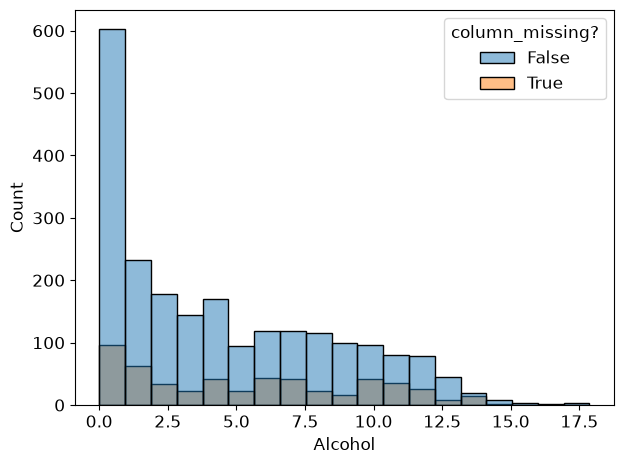

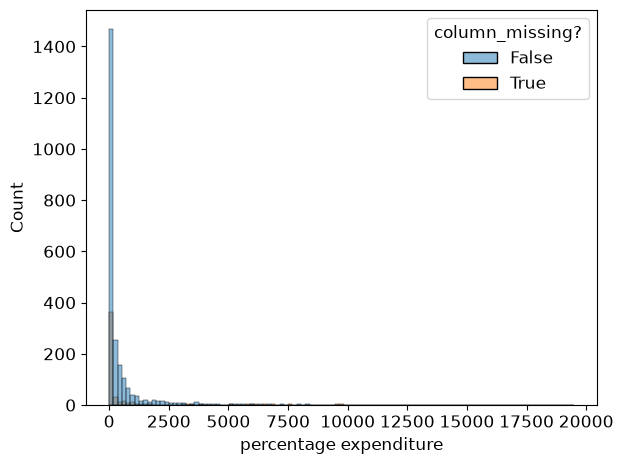

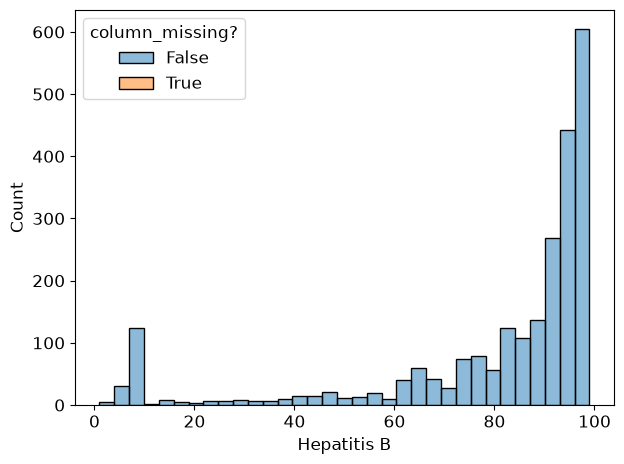

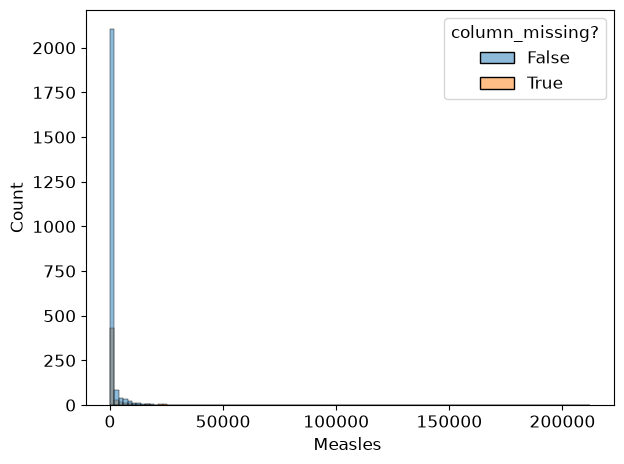

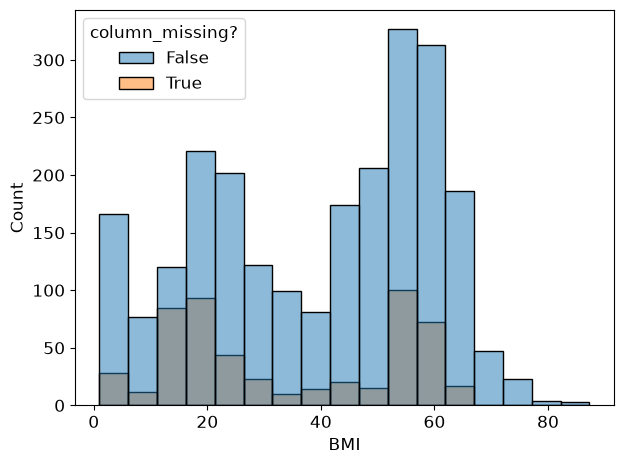

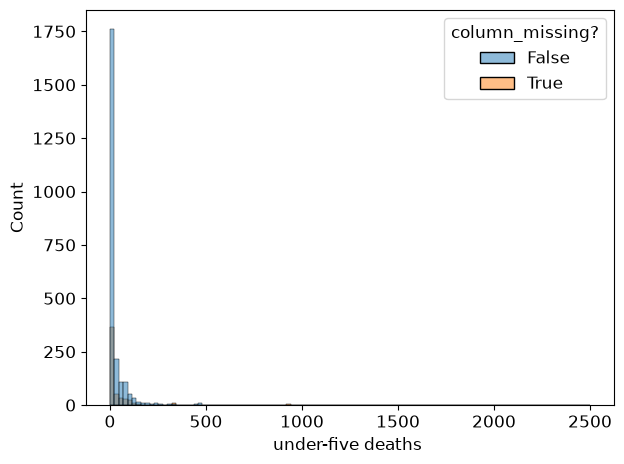

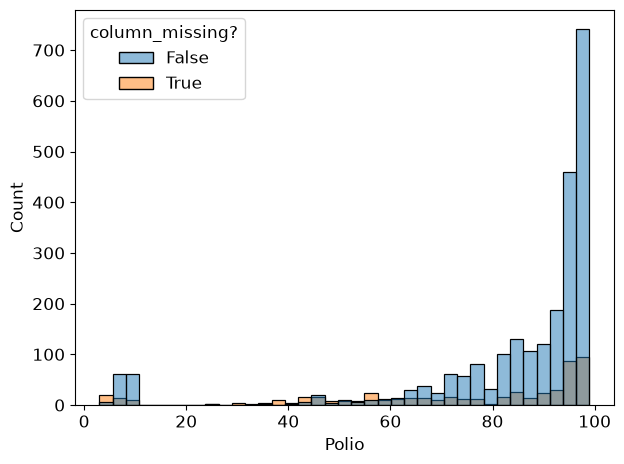

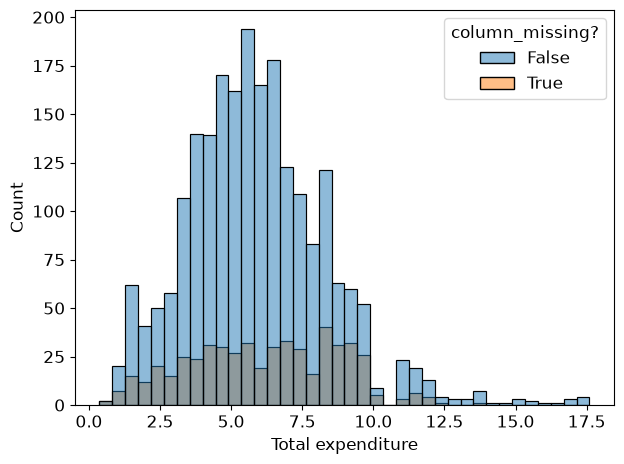

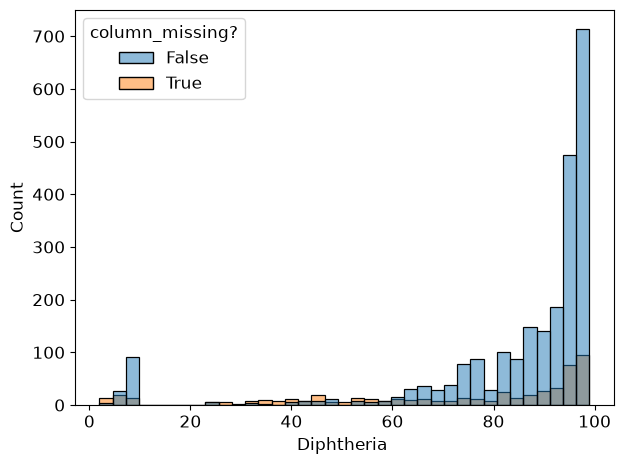

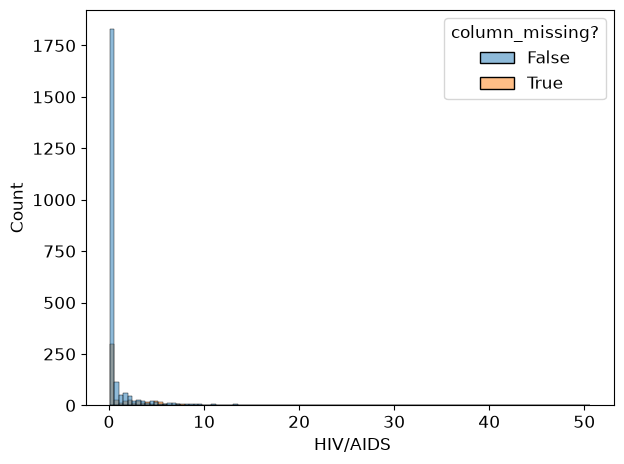

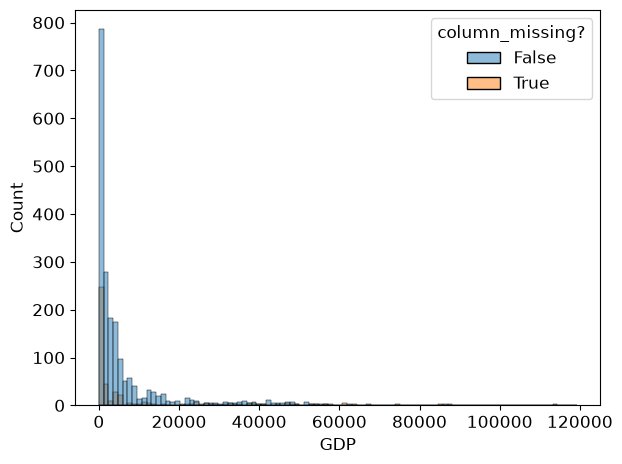

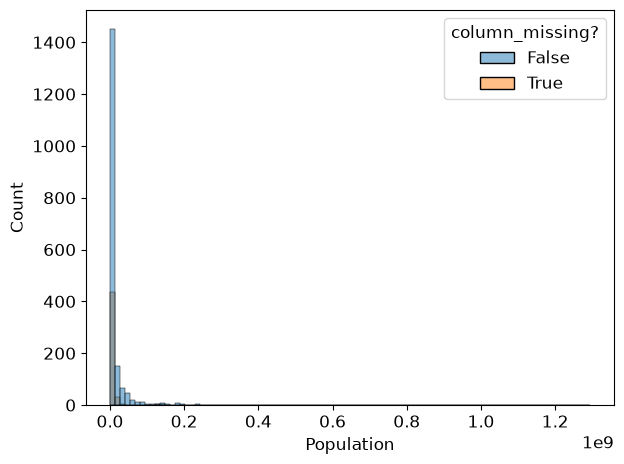

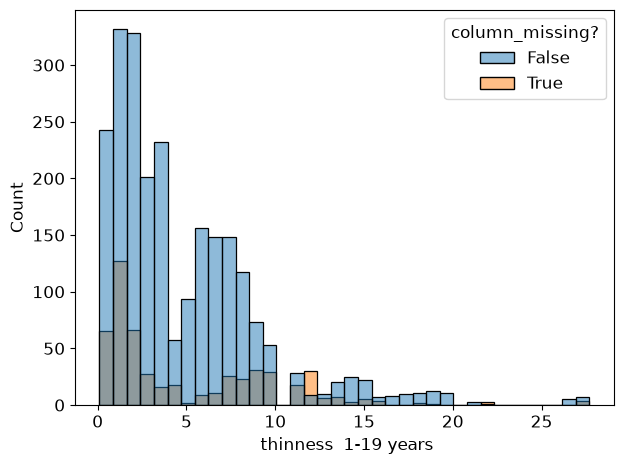

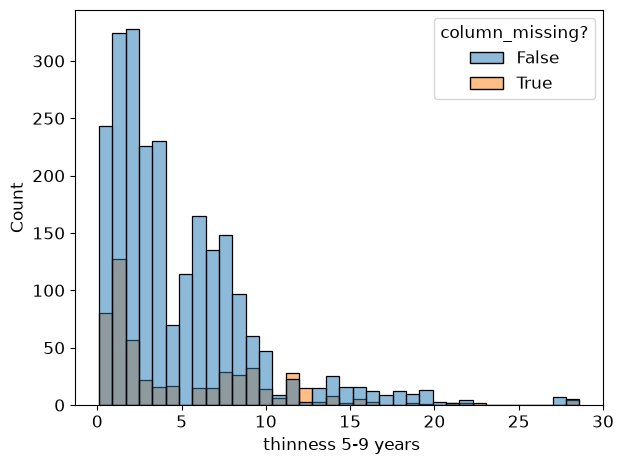

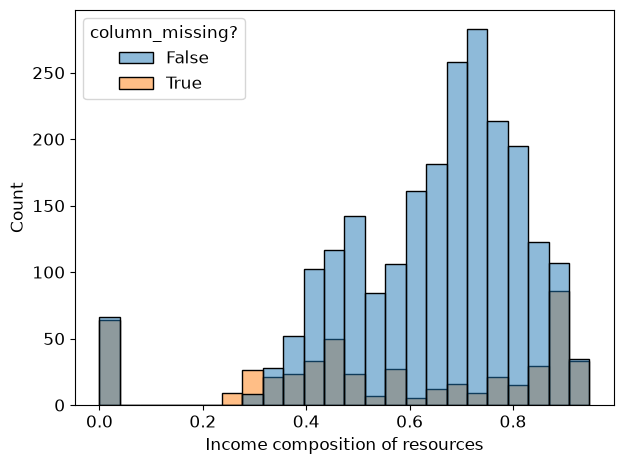

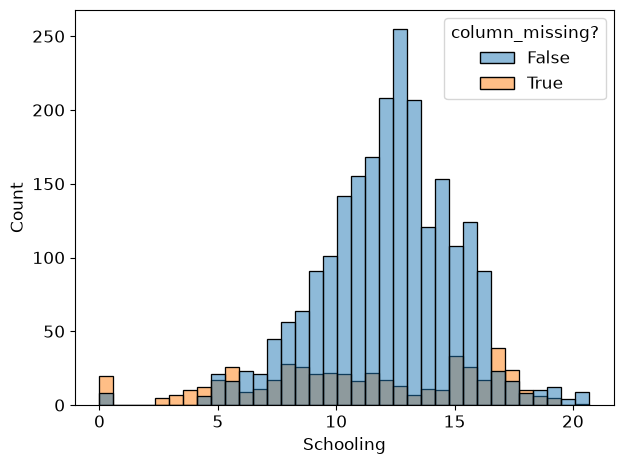

In [24]:
diagnose_mv(df, "Hepatitis B")

Year 2000 has a significant amount of missing Hepatitis B values. Rows with life expectancy < 60 have a very high percentage of missing Hepatitis B values. Adult mortality 300<x<400 has asignificant percentage of missing values.

Thinness 12 has a significant amount of missing Hepatitis B values

Income composition has significant amount of missing values from 0 to 0.35

Schooling has a significant amount of missing values from 0 to 6.

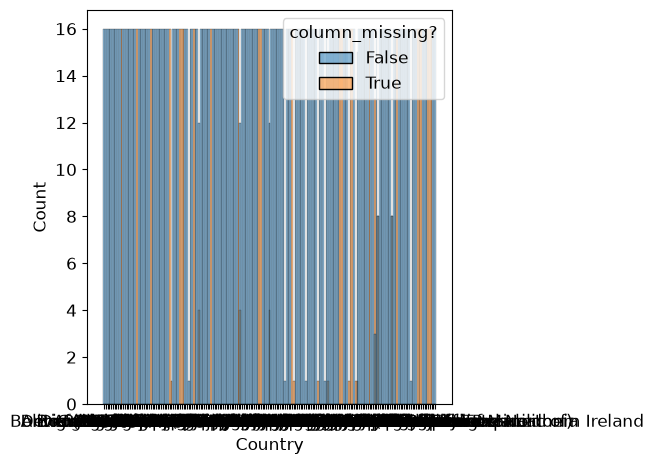

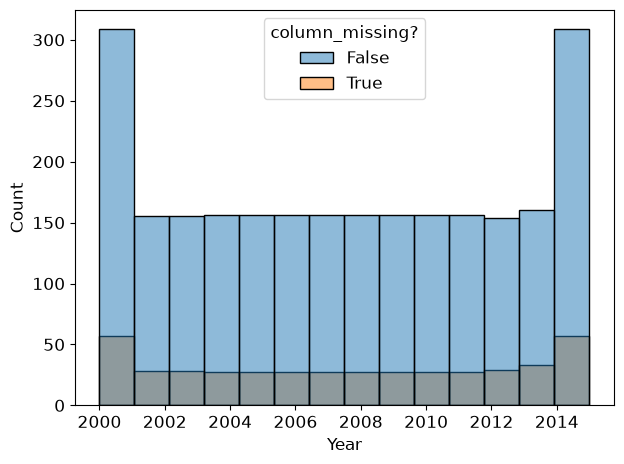

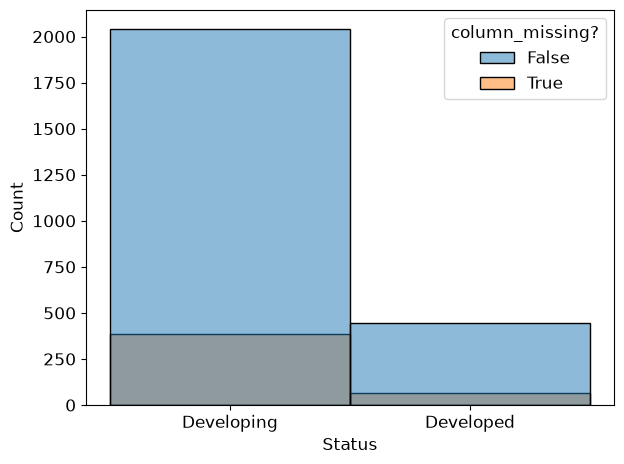

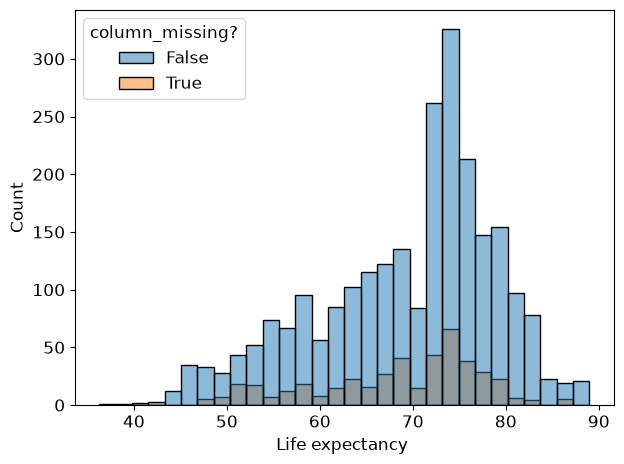

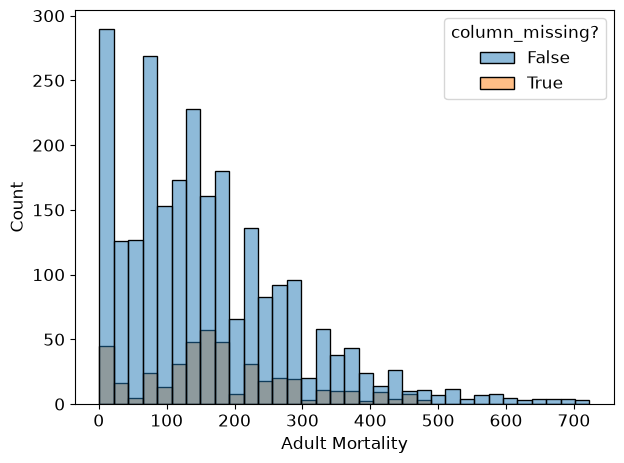

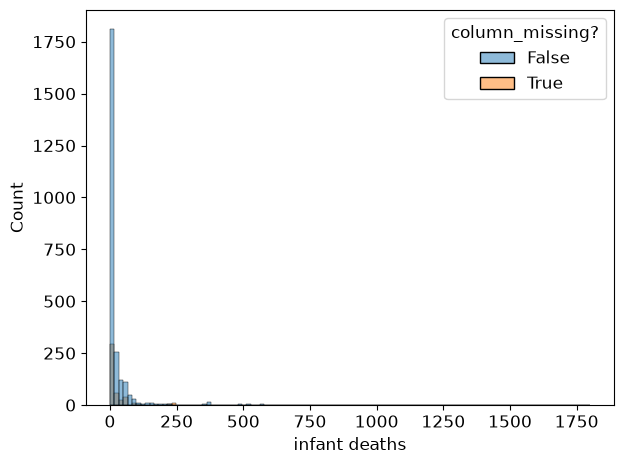

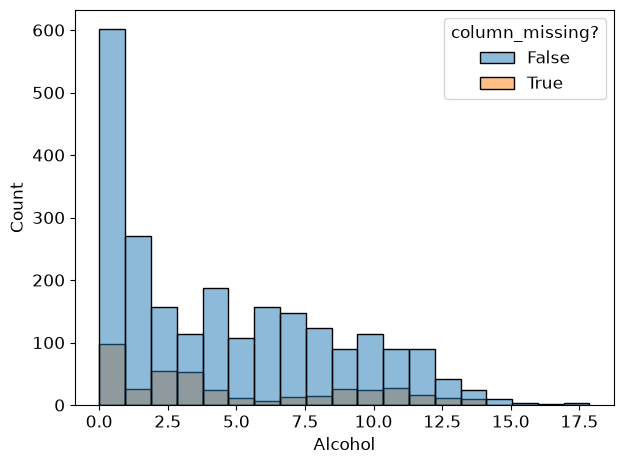

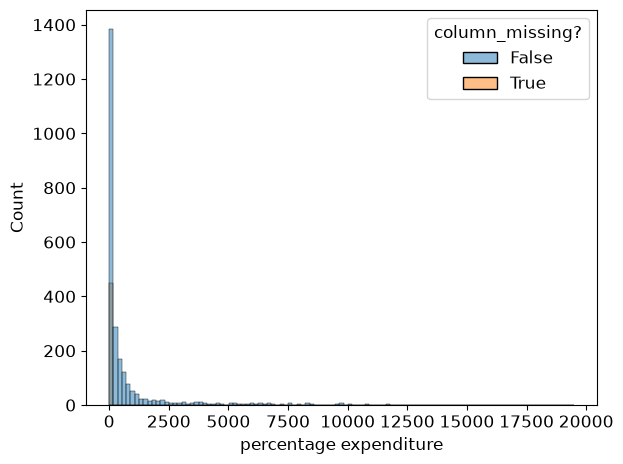

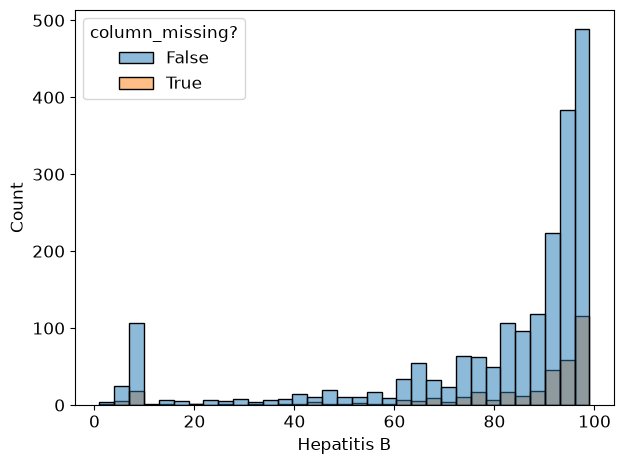

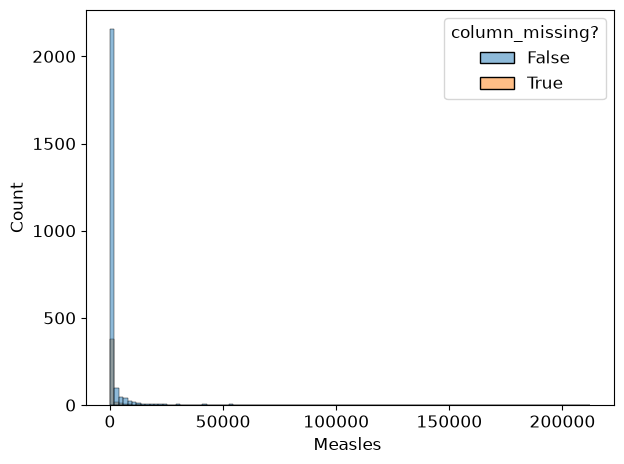

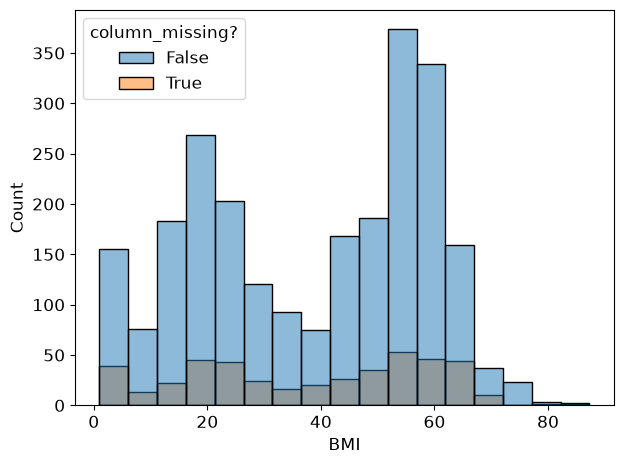

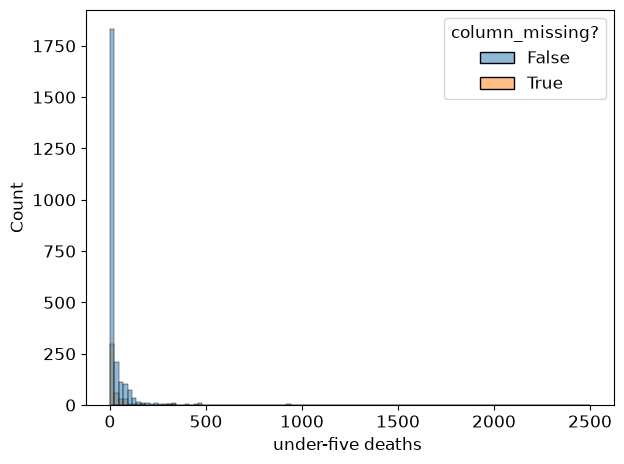

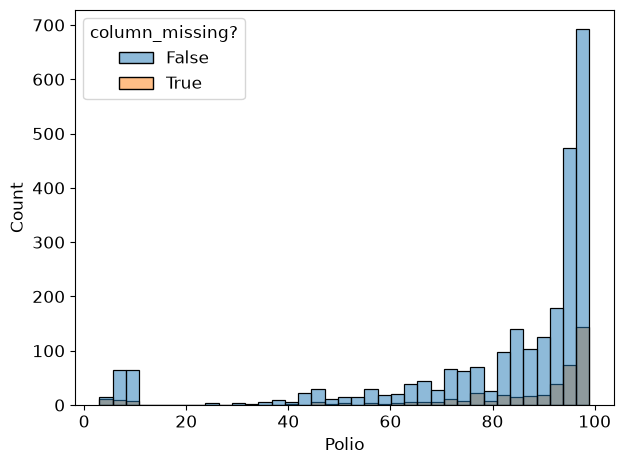

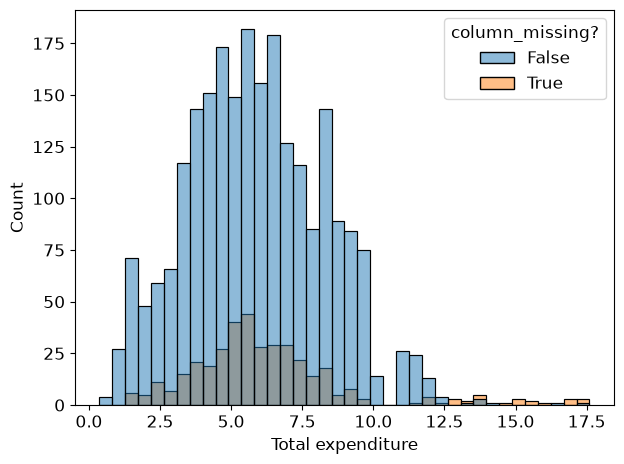

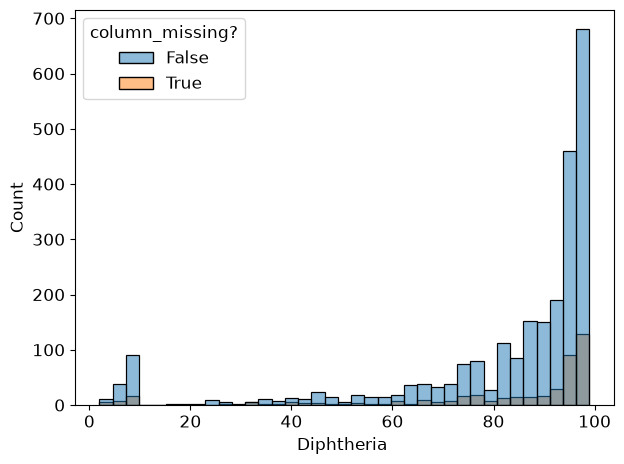

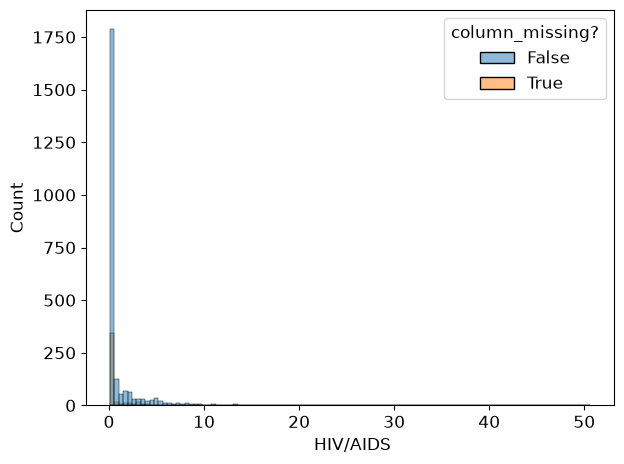

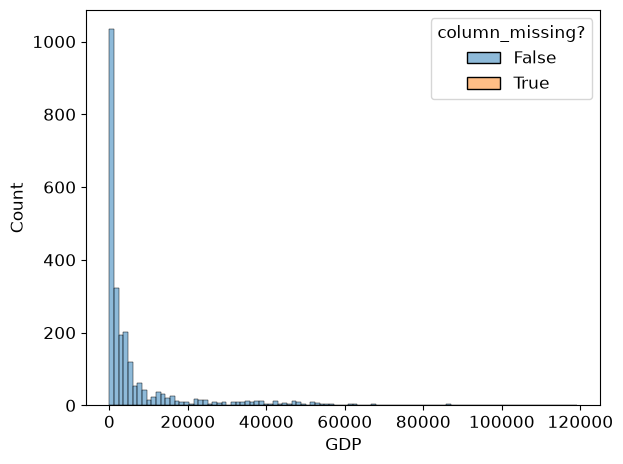

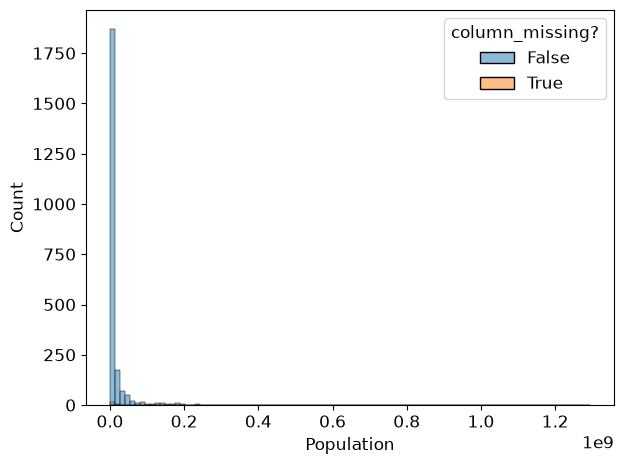

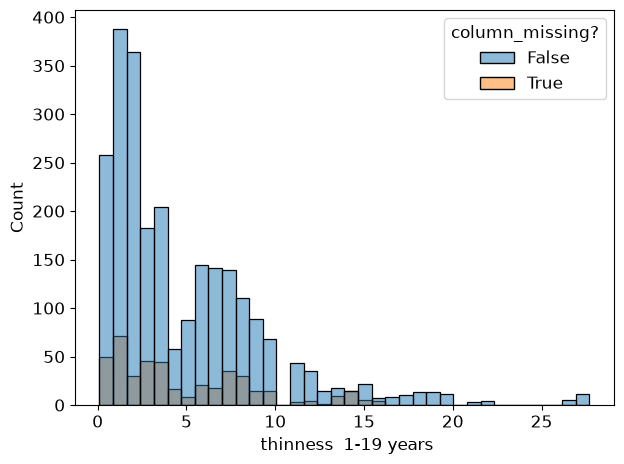

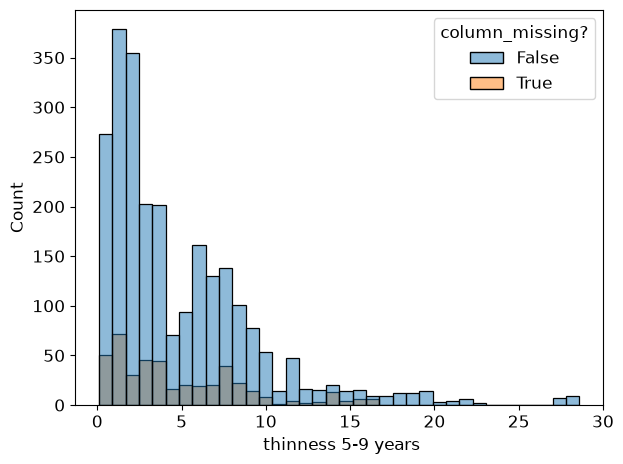

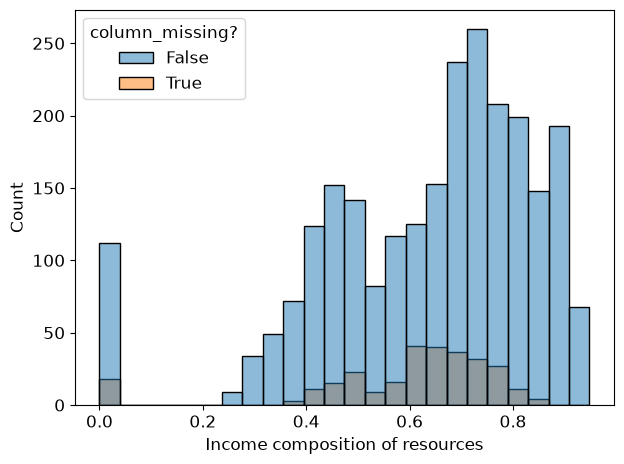

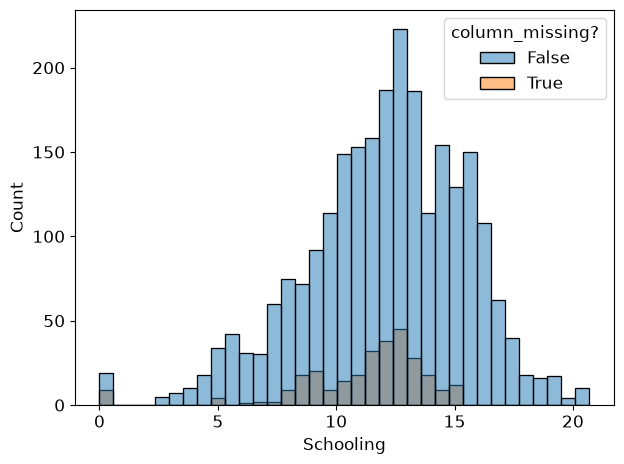

In [25]:
diagnose_mv(df, "GDP")

GDP feels like most missing-nonmissing distributions fit each other's shape

In [26]:
# We drop the "Country" feature because it's not beneficial for creating the model
df_life_expectancy = df.copy()
df_life_expectancy = df.drop('Country', axis=1)

In [37]:

cwmv = ["Population", "Hepatitis B", "GDP", "Total expenditure", "Alcohol", "Income composition of resources", "Polio", "Adult Mortality"]
def replace_w_mean(df, column, ref):
    df[column] = df[column].fillna(
        df.groupby(ref)[column].transform('mean')
    )
    return df

for i in cwmv:
  df=replace_w_mean(df, i, "Country")

In [38]:
# We drop all the rows of the features that have less than 10% missing values.
drop_features = missing_percent[missing_percent < 10].index
df_life_expectancy = df_life_expectancy.dropna(how = "any", subset = drop_features)

In [39]:
# We replace "Developing" with 0 and "Developed" with 1.
df_life_expectancy["Status"] = df_life_expectancy["Status"].map({
    "Developing" : 0,
    "Developed" : 1
})

In [40]:
df_life_expectancy

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,2015,NaN,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,2014,NaN,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,2013,NaN,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,2012,NaN,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,2011,NaN,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,2004,NaN,44.3,723.0,27,4.36,0.000000,68.0,31,27.1,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,2003,NaN,44.5,715.0,26,4.06,0.000000,7.0,998,26.7,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,2002,NaN,44.8,73.0,25,4.43,0.000000,73.0,304,26.3,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,2001,NaN,45.3,686.0,25,1.72,0.000000,76.0,529,25.9,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


In [35]:
# For the features with more than 10% missing values, we replace them with the mean of the column.
kept_features = missing_percent[missing_percent >= 10].index
for feature in kept_features:
    mean_feature = df_life_expectancy[feature].mean(skipna=True)
    df_life_expectancy[feature] = df_life_expectancy[feature].fillna(mean_feature)

In [36]:
# For the next one we need to do normalization and standardazation and continue on with question 3.